# 03 — Part 1: predicting infant death from information known before delivery

**Goal.** Measure how well information that is known *before the baby is born* predicts death before age one, in birth cohorts the models have never seen. Then rank which items carry the most predictive value.

**Thesis part.** Part 1 (prediction). Plan: `plan/analysis_plan.md`, section 3. Methods and pass/fail rules were fixed before this run.

**Inputs.** `data/parquet/cohort_<year>.parquet` (from `00_data_build`). All the code is in this notebook. The heavy sections save their results in `data/part1/` and `reports/`, so later sections and `main.ipynb` reuse them.

**Outputs.** `reports/part1_*.csv` and `reports/figures/part1_*.png`.

**How to run.** Run all cells. With `REBUILD = False` (default), a section whose results already exist only shows them (about 1 minute in total). With `REBUILD = True`, everything is recomputed: about 2.5 hours, peak memory about 2.5 GB. Run it from the terminal so you can watch it: `papermill --log-output -p REBUILD True 03_prediction.ipynb 03_prediction.ipynb` (in `notebooks/`).

**Terms.**
- *Prediction* asks "which babies are at high risk?". It does **not** say what causes death.
- *Set A* = items known in early pregnancy (age, race, education, payment, history, BMI, pre-pregnancy diabetes and hypertension, father's items). *Set B* = Set A + items known before delivery (1st-trimester smoking, start of prenatal care, WIC, gestational diabetes and hypertension, plurality, infections).
- *PR-AUC* (area under the precision–recall curve) is the main metric. With 0.55% deaths, a model that guesses gets PR-AUC ≈ 0.0055.
- *ROC-AUC*: the chance that a random death gets a higher score than a random survivor (0.5 = guessing, 1 = perfect).
- *Brier score*: the mean squared error of the predicted probabilities (lower is better).
- *Calibration*: whether predicted risks equal observed risks. Slope 1 and intercept 0 are perfect.

## 1. Setup

In [1]:
REBUILD = False

In [2]:
# Parameters
REBUILD = True


In [3]:
import gc
import json
import time
from dataclasses import dataclass
from pathlib import Path

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

ROOT = Path.cwd().parent
PARQUET = ROOT / "data" / "parquet"
WORK = ROOT / "data" / "part1"          # ignored by Git: tables, models, predictions
REPORTS = R = ROOT / "reports"
FIG = REPORTS / "figures"
SEED = 20261123
SURVIVOR_SAMPLE = 10                    # keep 1 in 10 survivors in training
N_BOOT = 1000
N_PERM = 20
pl.Config.set_tbl_rows(50); pl.Config.set_tbl_width_chars(180); pl.Config.set_float_precision(4)
NAMES = {"a_baseline_rate": "(a) baseline rate", "b_age_race_logistic": "(b) age + race logistic",
         "c_logistic": "(c) penalized logistic", "d_hgb": "(d) gradient boosting"}


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


def run_stage(stage, outputs):
    """Run a heavy stage if REBUILD is set or its outputs are missing; then free memory."""
    if REBUILD or not all(p.exists() for p in outputs):
        stage()
    else:
        log(f"{stage.__name__}: using saved results")
    gc.collect()

### Inputs: items known before delivery

**What.** Each input is a DuckDB expression on the Parquet text codes. Rules (plan, section 3):
- "Unknown / not stated" codes become missing (NaN).
- If an item's reporting flag is not 1 (the state did not collect it), the value becomes missing too.
- Set A = known in early pregnancy. Set B = Set A + items known before delivery.

In [4]:
@dataclass(frozen=True)
class Feature:
    name: str      # our short name
    sql: str       # DuckDB expression on the Parquet columns
    kind: str      # "num" (number) or "cat" (category code)
    in_set: str    # "A" or "B"
    label: str     # plain-English label for tables


def num(col, missing=(), flag=None, cast="FLOAT"):
    cond = " OR ".join([f"{col} IS NULL"] + [f"{col} = '{m}'" for m in missing])
    f = f"COALESCE({flag}, '1') <> '1' OR " if flag else ""
    return f"CASE WHEN {f}{cond} THEN NULL ELSE CAST({col} AS {cast}) END"


def yn(col, flag=None):
    f = f"WHEN COALESCE({flag}, '1') <> '1' THEN NULL " if flag else ""
    return f"CAST(CASE {f}WHEN {col} = 'Y' THEN 1 WHEN {col} = 'N' THEN 0 ELSE NULL END AS FLOAT)"


FEATURES = [
    # Set A: known in early pregnancy
    Feature("mage", num("MAGER"), "num", "A", "Mother's age (years)"),
    Feature("race", num("MRACEHISP", ["8"]), "cat", "A", "Mother's race/Hispanic origin"),
    Feature("nativity", num("MBSTATE_REC", ["3"]), "cat", "A", "Mother born outside the U.S."),
    Feature("educ", num("MEDUC", ["9"], "F_MEDUC"), "cat", "A", "Mother's education"),
    Feature("marital", num("DMAR", ["9"]), "cat", "A", "Marital status"),
    Feature("pay", num("PAY_REC", ["9"], "F_PAY_REC"), "cat", "A", "Payment source"),
    Feature("priorlive", num("PRIORLIVE", ["99"]), "num", "A", "Prior births now living"),
    Feature("priordead", num("PRIORDEAD", ["99"]), "num", "A", "Prior births now dead"),
    Feature("priorterm", num("PRIORTERM", ["99"]), "num", "A", "Prior terminations/fetal deaths"),
    Feature("lbo", num("LBO_REC", ["9"]), "num", "A", "Live birth order"),
    Feature("illb", num("ILLB_R11", ["99"]), "cat", "A", "Interval since last live birth"),
    Feature("ilp", num("ILP_R11", ["99"]), "cat", "A", "Interval since last pregnancy"),
    Feature("cig0", num("CIG_0", ["99"], "F_CIGS_0"), "num", "A", "Cigarettes/day before pregnancy"),
    Feature("bmi", num("BMI", ["99.9"], "F_PWGT"), "num", "A", "Pre-pregnancy BMI"),
    Feature("height", num("MHTR", ["99"], "F_M_HT"), "num", "A", "Mother's height (inches)"),
    Feature("pdiab", yn("RF_PDIAB", "F_RF_PDIAB"), "cat", "A", "Pre-pregnancy diabetes"),
    Feature("phype", yn("RF_PHYPE", "F_RF_PHYPE"), "cat", "A", "Pre-pregnancy hypertension"),
    Feature("ppb", yn("RF_PPB", "F_RF_PPB"), "cat", "A", "Previous preterm birth"),
    Feature("inft", yn("RF_INFT", "F_RF_INFT"), "cat", "A", "Infertility treatment"),
    Feature("cesarn", num("RF_CESARN", ["99"], "F_RF_NCESAR"), "num", "A", "Number of previous cesareans"),
    Feature("fage", num("FAGECOMB", ["99"]), "num", "A", "Father's age"),
    Feature("frace", num("FRACEHISP", ["8", "9"]), "cat", "A", "Father's race/Hispanic origin"),
    Feature("feduc", num("FEDUC", ["9"], "F_FEDUC"), "cat", "A", "Father's education"),
    Feature("year", "CAST(cohort AS FLOAT)", "num", "A", "Birth cohort year"),
    # Set B adds: known before delivery
    Feature("cig1", num("CIG_1", ["99"], "F_CIGS_1"), "num", "B", "Cigarettes/day, 1st trimester"),
    Feature("precare", num("PRECARE", ["99"], "F_MPCB"), "num", "B", "Month prenatal care began"),
    Feature("wic", yn("WIC", "F_WIC"), "cat", "B", "WIC food program"),
    Feature("gdiab", yn("RF_GDIAB", "F_RF_GDIAB"), "cat", "B", "Gestational diabetes"),
    Feature("ghype", yn("RF_GHYPE", "F_RF_GHYPE"), "cat", "B", "Gestational hypertension"),
    Feature("plural", num("DPLURAL"), "num", "B", "Plurality (twins etc.)"),
    Feature("ip_gon", yn("IP_GON", "F_IP_GON"), "cat", "B", "Gonorrhea"),
    Feature("ip_syph", yn("IP_SYPH", "F_IP_SYPH"), "cat", "B", "Syphilis"),
    Feature("ip_chlam", yn("IP_CHLAM", "F_IP_CHLAM"), "cat", "B", "Chlamydia"),
    Feature("ip_hepb", yn("IP_HEPB", "F_IP_HEPB"), "cat", "B", "Hepatitis B"),
    Feature("ip_hepc", yn("IP_HEPC", "F_IP_HEPC"), "cat", "B", "Hepatitis C"),
]

SET_A = [f.name for f in FEATURES if f.in_set == "A"]
SET_B = SET_A + [f.name for f in FEATURES if f.in_set == "B"]
KIND = {f.name: f.kind for f in FEATURES}
LABEL = {f.name: f.label for f in FEATURES}
# Nominal categories for the tree model (ordered codes such as education stay numeric there).
TREE_CATEGORICAL = {"race", "nativity", "marital", "pay", "illb", "ilp", "frace"}
SPLINE = {"mage", "bmi"}

### Metrics

**What.** Fast weighted PR-AUC (average precision) and ROC-AUC for very large test sets, the Brier score, and calibration.

**Bootstrap.** Each resample gives every test birth a Poisson(1) weight (0, 1, 2, …): how often it appears in the resample. With millions of births, this is the standard fast version of resampling with replacement. Scores are sorted once per model, so each resample needs only cumulative sums.

**Calibration fit.** A small Newton solver fits the 1–2 parameter logistic models. It gives the same result as statsmodels GLM, which needs too much memory at 7 million rows.

In [5]:
class SortedScores:
    """Pre-sorted scores of one model, for repeated weighted AP / ROC-AUC."""

    def __init__(self, y, p):
        order = np.argsort(-p, kind="stable")
        self.order = order
        self.y = y[order].astype(np.float64)
        ps = p[order]
        # last index of each group of tied scores
        self.ends = np.flatnonzero(np.r_[ps[1:] != ps[:-1], True])

    def metrics(self, w=None):
        """Return (average precision, ROC-AUC) for weights w (None = all 1)."""
        w = np.ones_like(self.y) if w is None else w[self.order]
        tp = np.cumsum(w * self.y)[self.ends]
        fp = np.cumsum(w * (1 - self.y))[self.ends]
        P, N = tp[-1], fp[-1]
        recall = tp / P
        # A bootstrap resample can give the top-scored group zero weight (0/0).
        # Recall does not change there, so its precision adds nothing; set it to 0.
        precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
        ap = np.sum(np.diff(np.r_[0.0, recall]) * precision)
        tpr, fpr = np.r_[0.0, recall], np.r_[0.0, fp / N]
        auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)
        return ap, auc


def brier(y, p, w=None):
    w = np.ones_like(p) if w is None else w
    return float(np.sum(w * (p - y) ** 2) / np.sum(w))


def calibration(y, p):
    """Calibration intercept (calibration-in-the-large) and slope, with 95% CIs.

    Slope: logistic regression of y on logit(p); 1 = perfect.
    Intercept: logistic regression of y with logit(p) as offset; 0 = perfect.
    """
    p = np.clip(p, 1e-7, 1 - 1e-7)
    lp = np.log(p / (1 - p))
    (a, b), cov_s = _logit_newton(y, lp, offset=False)
    (c,), cov_i = _logit_newton(y, lp, offset=True)
    se_b, se_c = np.sqrt(cov_s[1, 1]), np.sqrt(cov_i[0, 0])
    return {"cal_slope": b, "cal_slope_lo": b - 1.96 * se_b, "cal_slope_hi": b + 1.96 * se_b,
            "cal_intercept": c, "cal_intercept_lo": c - 1.96 * se_c, "cal_intercept_hi": c + 1.96 * se_c,
            "observed_over_expected": float(y.sum() / p.sum())}


def _logit_newton(y, lp, offset, iters=50):
    """Maximum-likelihood logistic fit with 1-2 parameters, low memory.

    offset=False: logit P(y) = a + b*lp   (returns a, b)
    offset=True:  logit P(y) = c + lp     (returns c)
    Returns the estimates and their covariance (inverse Hessian).
    Same model as statsmodels GLM Binomial; statsmodels needs too much memory at 7 M rows.
    """
    beta = np.array([0.0, 1.0]) if not offset else np.array([0.0])
    for _ in range(iters):
        eta = (beta[0] + beta[1] * lp) if not offset else (beta[0] + lp)
        mu = 1.0 / (1.0 + np.exp(-eta))
        r, v = y - mu, mu * (1 - mu)
        if offset:
            g, H = np.array([r.sum()]), np.array([[v.sum()]])
        else:
            g = np.array([r.sum(), (r * lp).sum()])
            H = np.array([[v.sum(), (v * lp).sum()], [(v * lp).sum(), (v * lp * lp).sum()]])
        step = np.linalg.solve(H, g)
        beta = beta + step
        if np.max(np.abs(step)) < 1e-10:
            break
    return beta, np.linalg.inv(H)

### Models

**What.** (b) logistic regression on mother's age group and race only; (c) penalized logistic regression on all inputs, with splines for age and BMI and missing-value indicators; (d) histogram gradient boosting with early stopping. Training weights are normalized to mean 1, because with raw weights the logistic solver stopped before it converged.

In [6]:
SETS = {"A": SET_A, "B": SET_B, "B_no_marital": [f for f in SET_B if f != "marital"]}
LOGIT_C = [0.01, 0.1, 1.0]              # penalty strengths tried for model (c)
HGB_GRID = [                            # settings tried for model (d)
    {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 1000},
    {"learning_rate": 0.1, "max_leaf_nodes": 63, "min_samples_leaf": 500},
    {"learning_rate": 0.05, "max_leaf_nodes": 127, "min_samples_leaf": 2000},
]


def logistic_pipeline(feats, C):
    spl = [i for i, f in enumerate(feats) if f in SPLINE]
    numc = [i for i, f in enumerate(feats) if KIND[f] == "num" and f not in SPLINE]
    cat = [i for i, f in enumerate(feats) if KIND[f] == "cat"]
    pre = ColumnTransformer([
        ("spline", Pipeline([("imp", SimpleImputer(strategy="median")),
                             ("spl", SplineTransformer(n_knots=5, degree=3))]), spl),
        ("spline_missing", MissingIndicator(features="all"), spl),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), numc),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=-1)),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ], sparse_threshold=1.0)
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=C, max_iter=5000, tol=1e-6))])


def baseline_b_pipeline():
    # model (b): mother's age group + race/Hispanic origin only, as categories
    pre = ColumnTransformer([("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=-1)),
                                                ("oh", OneHotEncoder(handle_unknown="ignore"))]), [0, 1])])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=1.0, max_iter=5000, tol=1e-6))])


def hgb(feats, params):
    mask = [f in TREE_CATEGORICAL for f in feats]
    return HistGradientBoostingClassifier(
        **params, l2_regularization=1.0, max_iter=2000, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=30, scoring="loss", categorical_features=mask, random_state=SEED)


def fit(model, X, y, w):
    if isinstance(model, Pipeline):
        # Normalized weights (mean 1) and a strict tolerance: with raw weights the
        # default solver stopped after ~27 iterations, before convergence.
        return model.fit(X, y, lr__sample_weight=w / w.mean())
    return model.fit(X, y, sample_weight=w)


def predict(model, X, chunk=1_000_000):
    return np.concatenate([model.predict_proba(X[i:i + chunk])[:, 1] for i in range(0, len(X), chunk)])


def load(name, feats=None):
    df = pl.read_parquet(WORK / f"{name}.parquet")
    feats = feats or SET_B
    X = df.select(feats).to_numpy().astype(np.float32)
    return df, X, df["death"].to_numpy().astype(np.float64), df["w"].cast(pl.Float64).to_numpy()

## 2. Data split by time

**What.** Training uses births 2016–2020: all deaths and 1 in 10 survivors, with survivors weighted ×10, so that the model still learns the true death rate. Tuning uses all 2021 births. The test uses all 2022–2023 births, once, at the end.

**Why.** A split by time copies real use: a model built on past births is applied to future births. A random split would hide changes over time.

In [7]:
def stage_data():
    WORK.mkdir(parents=True, exist_ok=True)
    cols = ",\n  ".join(f"{f.sql} AS {f.name}" for f in FEATURES)
    base = f"""
      SELECT {cols},
        CAST(MAGER9 AS INT) AS agegrp, death, cohort,
        hash(cohort, file_row_number) % {SURVIVOR_SAMPLE} = 0 AS sampled
      FROM read_parquet('{PARQUET}/cohort_*.parquet', union_by_name = true, file_row_number = true)
      WHERE CAST(RESTATUS AS INT) < 4"""
    con = duckdb.connect()
    con.sql("SET threads TO 8")
    parts = {
        "train": f"SELECT *, CASE WHEN death THEN 1.0 ELSE {SURVIVOR_SAMPLE}.0 END AS w FROM ({base}) "
                 f"WHERE cohort BETWEEN 2016 AND 2020 AND (death OR sampled)",
        "tune": f"SELECT *, 1.0 AS w FROM ({base}) WHERE cohort = 2021",
        "test": f"SELECT *, 1.0 AS w FROM ({base}) WHERE cohort IN (2022, 2023)",
    }
    for name, q in parts.items():
        con.sql(f"COPY ({q}) TO '{WORK / name}.parquet' (FORMAT parquet)")
        n, d = con.sql(f"SELECT COUNT(*), SUM(death::INT) FROM '{WORK / name}.parquet'").fetchall()[0]
        log(f"{name}: {n:,} rows, {d:,} deaths")


run_stage(stage_data, [WORK / f"{n}.parquet" for n in ("train", "tune", "test")])

22:55:32 train: 1,990,809 rows, 106,391 deaths


22:55:33 tune: 3,664,292 rows, 19,965 deaths


22:55:34 test: 7,263,775 rows, 40,011 deaths


In [8]:
pl.DataFrame({
    "part": ["train (2016–2020, sampled)", "tune (2021)", "test (2022–2023)"],
    "rows": [pl.scan_parquet(ROOT / f"data/part1/{n}.parquet").select(pl.len()).collect().item() for n in ("train", "tune", "test")],
    "deaths": [pl.scan_parquet(ROOT / f"data/part1/{n}.parquet").select(pl.col("death").sum()).collect().item() for n in ("train", "tune", "test")],
})

part,rows,deaths
str,i64,i64
"""train (2016–2020, sampled)""",1990809,106391
"""tune (2021)""",3664292,19965
"""test (2022–2023)""",7263775,40011


## 3. Tuning on 2021

**What.** For each model type and input set we tried a few settings: the penalty strength `C` for logistic regression, and the tree size and learning rate for gradient boosting. We kept the setting with the highest PR-AUC on 2021.

**Why.** Choosing settings on 2021, not on the test years, keeps the test honest.

In [9]:
def stage_fit():
    for old in (WORK / "test_preds.parquet", WORK / "bootstrap.npz"):
        old.unlink(missing_ok=True)
    tr, _, ytr, wtr = load("train")
    tu, _, ytu, _ = load("tune")
    rows, best = [], {}
    rate = float(np.sum(wtr * ytr) / np.sum(wtr))
    joblib.dump(rate, WORK / "model_a_rate.joblib")
    rows.append({"model": "a_baseline_rate", "set": "-", "params": "", "tune_pr_auc": SortedScores(ytu, np.full(len(ytu), rate)).metrics()[0]})

    Xb_tr = tr.select("agegrp", "race").to_numpy().astype(np.float32)
    Xb_tu = tu.select("agegrp", "race").to_numpy().astype(np.float32)
    m = fit(baseline_b_pipeline(), Xb_tr, ytr, wtr)
    ap = SortedScores(ytu, predict(m, Xb_tu)).metrics()[0]
    rows.append({"model": "b_age_race_logistic", "set": "-", "params": "", "tune_pr_auc": ap})
    joblib.dump(m, WORK / "model_b.joblib")
    log("b", round(ap, 4))

    for set_name, feats in SETS.items():
        Xtr = tr.select(feats).to_numpy().astype(np.float32)
        Xtu = tu.select(feats).to_numpy().astype(np.float32)
        kinds = [("c_logistic", c, lambda c=c: logistic_pipeline(feats, c)) for c in LOGIT_C] if set_name != "B_no_marital" else []
        kinds += [("d_hgb", json.dumps(p), lambda p=p: hgb(feats, p)) for p in HGB_GRID]
        for kind, params, make in kinds:
            t = time.time()
            m = fit(make(), Xtr, ytr, wtr)
            ap = SortedScores(ytu, predict(m, Xtu)).metrics()[0]
            extra = {"n_iter": int(m.n_iter_)} if hasattr(m, "n_iter_") and kind == "d_hgb" else {}
            rows.append({"model": kind, "set": set_name, "params": str(params), "tune_pr_auc": ap, **extra})
            log(kind, set_name, params, round(ap, 4), f"{time.time() - t:.0f}s")
            key = (kind, set_name)
            if key not in best or ap > best[key][0]:
                best[key] = (ap, params)
                joblib.dump(m, WORK / f"model_{kind}_{set_name}.joblib")
    pl.DataFrame(rows).write_csv(REPORTS / "part1_tuning.csv")
    log("done fit")


run_stage(stage_fit, [REPORTS / "part1_tuning.csv"])

22:55:36 b 0.0085


22:55:52 c_logistic A 0.01 0.0172 16s


22:56:19 c_logistic A 0.1 0.0179 27s


22:56:45 c_logistic A 1.0 0.018 26s


22:57:06 d_hgb A {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 1000} 0.0279 21s


22:57:24 d_hgb A {"learning_rate": 0.1, "max_leaf_nodes": 63, "min_samples_leaf": 500} 0.0281 18s


... (7 outputs left out)

23:02:55 d_hgb B_no_marital {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 1000} 0.0352 38s


23:03:22 d_hgb B_no_marital {"learning_rate": 0.1, "max_leaf_nodes": 63, "min_samples_leaf": 500} 0.0342 28s


23:04:30 d_hgb B_no_marital {"learning_rate": 0.05, "max_leaf_nodes": 127, "min_samples_leaf": 2000} 0.037 68s


23:04:30 done fit


In [10]:
tun = pl.read_csv(R / "part1_tuning.csv")
tun.with_columns(pl.col("model").replace(NAMES)).sort("set", "model", "tune_pr_auc", descending=[False, False, True])

model,set,params,tune_pr_auc,n_iter
str,str,str,f64,i64
"""(a) baseline rate""","""-""","""""",0.0054,null
"""(b) age + race logistic""","""-""","""""",0.0085,null
"""(c) penalized logistic""","""A""","""1.0""",0.0180,null
"""(c) penalized logistic""","""A""","""0.1""",0.0179,null
"""(c) penalized logistic""","""A""","""0.01""",0.0172,null
"""(d) gradient boosting""","""A""","""{""learning_rate"": 0.05, ""max_l…",0.0287,271
"""(d) gradient boosting""","""A""","""{""learning_rate"": 0.1, ""max_le…",0.0281,148
"""(d) gradient boosting""","""A""","""{""learning_rate"": 0.1, ""max_le…",0.0279,234
"""(c) penalized logistic""","""B""","""1.0""",0.0237,null


**Result.** Gradient boosting is best for both sets on 2021: PR-AUC 0.0287 (Set A) and 0.0370 (Set B), both with the slowest, largest setting (learning rate 0.05, 127 leaves). The penalty `C` changes logistic regression only a little (Set B: 0.0227 to 0.0237), so the penalty is not the reason that logistic regression is weaker. Leaving out marital status costs almost nothing (0.0370 vs 0.0370).

## 4. Test results (2022–2023), with 95% bootstrap intervals

**What.** Every model predicts every 2022–2023 birth. We compute PR-AUC, ROC-AUC and the Brier score, with 95% intervals from 1,000 bootstrap resamples, and the calibration intercept and slope.

**Expected (stated in the plan).** Set B beats Set A. ROC-AUC is moderate (about 0.65–0.75), because gestational age and birth weight are excluded on purpose.

In [11]:
MODELS = [("b_age_race_logistic", "-"), ("c_logistic", "A"), ("d_hgb", "A"),
          ("c_logistic", "B"), ("d_hgb", "B"), ("d_hgb", "B_no_marital")]


def test_predictions():
    f = WORK / "test_preds.parquet"
    if f.exists():
        return pl.read_parquet(f)
    te = pl.read_parquet(WORK / "test.parquet")
    out = {"death": te["death"], "cohort": te["cohort"], "race": te["race"], "pay": te["pay"]}
    out["a_baseline_rate|-"] = np.full(te.height, joblib.load(WORK / "model_a_rate.joblib"))
    out["b_age_race_logistic|-"] = predict(joblib.load(WORK / "model_b.joblib"),
                                           te.select("agegrp", "race").to_numpy().astype(np.float32))
    for kind, s in MODELS[1:]:
        X = te.select(SETS[s]).to_numpy().astype(np.float32)
        out[f"{kind}|{s}"] = predict(joblib.load(WORK / f"model_{kind}_{s}.joblib"), X)
        log("predicted", kind, s)
    df = pl.DataFrame(out)
    df.write_parquet(f)
    return df


def best_model_key():
    tun = pl.read_csv(REPORTS / "part1_tuning.csv")
    b = tun.filter(pl.col("set") == "B").sort("tune_pr_auc", descending=True).row(0, named=True)
    return f"{b['model']}|B"


def stage_evaluate():
    pr = test_predictions()
    y = pr["death"].to_numpy().astype(np.float64)
    keys = [c for c in pr.columns if "|" in c]
    best = best_model_key()
    log("best model by 2021 PR-AUC:", best)
    sorted_ = {k: SortedScores(y, pr[k].to_numpy()) for k in keys}
    point = {k: sorted_[k].metrics() + (brier(y, pr[k].to_numpy()),) for k in keys}

    cache = WORK / "bootstrap.npz"
    if cache.exists():                      # reuse a finished bootstrap (same seed, same predictions)
        z = np.load(cache)
        boot = {k: z[k.replace("|", "__")] for k in keys}
    else:
        rng = np.random.default_rng(SEED)
        boot = {k: [] for k in keys}
        for r in range(N_BOOT):
            w = rng.poisson(1.0, len(y)).astype(np.float64)
            for k in keys:
                ap, auc = sorted_[k].metrics(w)
                boot[k].append((ap, auc, brier(y, pr[k].to_numpy(), w)))
            if r % 100 == 0:
                log("bootstrap", r)
        boot = {k: np.array(v) for k, v in boot.items()}
        np.savez(cache, **{k.replace("|", "__"): v for k, v in boot.items()})
    log("bootstrap ready", {k: v.shape for k, v in boot.items()})

    rows = []
    for k in keys:
        lo, hi = np.percentile(boot[k], [2.5, 97.5], axis=0)
        cal = calibration(y, pr[k].to_numpy()) if not k.startswith("a_") else {}
        rows.append({"model": k.split("|")[0], "set": k.split("|")[1], "is_best": k == best,
                     "pr_auc": point[k][0], "pr_auc_lo": lo[0], "pr_auc_hi": hi[0],
                     "roc_auc": point[k][1], "roc_auc_lo": lo[1], "roc_auc_hi": hi[1],
                     "brier": point[k][2], "brier_lo": lo[2], "brier_hi": hi[2], **cal})
    comp = pl.DataFrame(rows)
    comp.write_csv(REPORTS / "part1_model_comparison.csv")

    # paired differences in PR-AUC (bootstrap uses the same weights for every model)
    diffs = []
    for k in keys:
        if k == best:
            continue
        d = boot[best][:, 0] - boot[k][:, 0]
        diffs.append({"best": best, "compared_with": k, "pr_auc_diff": point[best][0] - point[k][0],
                      "lo": np.percentile(d, 2.5), "hi": np.percentile(d, 97.5)})
    pl.DataFrame(diffs).write_csv(REPORTS / "part1_pr_auc_differences.csv")

    # per test year
    yrs = []
    for yr in (2022, 2023):
        m = (pr["cohort"] == yr).to_numpy()
        for k in keys:
            p = pr[k].to_numpy()[m]
            ap, auc = SortedScores(y[m], p).metrics()
            cal = calibration(y[m], p) if not k.startswith("a_") else {}
            yrs.append({"test_year": yr, "model": k, "pr_auc": ap, "roc_auc": auc, "brier": brier(y[m], p), **cal})
    pl.DataFrame(yrs).write_csv(REPORTS / "part1_test_years.csv")

    # calibration by decile of predicted risk, for the best Set A and Set B models
    dec = []
    for k in [best, best.replace("|B", "|A")]:
        p = pr[k].to_numpy()
        q = np.quantile(p, np.linspace(0, 1, 11))
        idx = np.clip(np.searchsorted(q, p, side="right") - 1, 0, 9)
        for d in range(10):
            m = idx == d
            dec.append({"model": k, "decile": d + 1, "n": int(m.sum()), "mean_predicted": float(p[m].mean()),
                        "observed_rate": float(y[m].mean()), "deaths": int(y[m].sum())})
    pl.DataFrame(dec).write_csv(REPORTS / "part1_calibration_deciles.csv")

    # subgroups for the best model
    sub = []
    p = pr[best].to_numpy()
    for var in ("race", "pay"):
        vals = pr[var].to_numpy()
        for v in sorted(set(vals[~np.isnan(vals)].tolist())) + [np.nan]:
            m = np.isnan(vals) if np.isnan(v) else vals == v
            if y[m].sum() < 20:
                continue
            ap, auc = SortedScores(y[m], p[m]).metrics()
            sub.append({"variable": var, "code": None if np.isnan(v) else int(v), "births": int(m.sum()),
                        "deaths": int(y[m].sum()), "pr_auc": ap, "roc_auc": auc,
                        "observed_over_expected": float(y[m].sum() / p[m].sum())})
    pl.DataFrame(sub).write_csv(REPORTS / "part1_subgroups.csv")
    log("done evaluate")


run_stage(stage_evaluate, [REPORTS / "part1_model_comparison.csv", REPORTS / "part1_subgroups.csv"])

23:04:37 predicted c_logistic A


23:05:06 predicted d_hgb A


23:05:14 predicted c_logistic B


23:05:43 predicted d_hgb B


23:06:18 predicted d_hgb B_no_marital


23:06:18 best model by 2021 PR-AUC: d_hgb|B


... (8 outputs left out)

23:16:38 bootstrap 800


23:17:54 bootstrap 900


23:19:09 bootstrap ready {'a_baseline_rate|-': (1000, 3), 'b_age_race_logistic|-': (1000, 3), 'c_logistic|A': (1000, 3), 'd_hgb|A': (1000, 3), 'c_logistic|B': (1000, 3), 'd_hgb|B': (1000, 3), 'd_hgb|B_no_marital': (1000, 3)}


23:19:22 done evaluate


In [12]:
comp = pl.read_csv(R / "part1_model_comparison.csv")
comp.with_columns(pl.col("model").replace(NAMES)).select(
    "model", "set", "is_best", "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "roc_auc_lo", "roc_auc_hi",
    "brier", "cal_intercept", "cal_slope", "observed_over_expected")

model,set,is_best,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,roc_auc_lo,roc_auc_hi,brier,cal_intercept,cal_slope,observed_over_expected
str,str,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""(a) baseline rate""","""-""",false,0.0055,0.0055,0.0056,0.5000,0.5000,0.5000,0.0055,null,null,null
"""(b) age + race logistic""","""-""",false,0.0087,0.0086,0.0089,0.6107,0.6079,0.6136,0.0055,-0.0049,1.0535,0.9951
"""(c) penalized logistic""","""A""",false,0.0181,0.0175,0.0187,0.6998,0.6972,0.7025,0.0054,0.0784,0.9641,1.0805
"""(d) gradient boosting""","""A""",false,0.0294,0.0281,0.0308,0.7107,0.7080,0.7133,0.0054,0.0388,0.9438,1.0388
"""(c) penalized logistic""","""B""",false,0.0239,0.0231,0.0249,0.7166,0.7139,0.7194,0.0054,0.0956,0.9481,1.0986
"""(d) gradient boosting""","""B""",true,0.0380,0.0364,0.0396,0.7392,0.7366,0.7418,0.0054,0.0298,0.9420,1.0295
"""(d) gradient boosting""","""B_no_marital""",false,0.0378,0.0362,0.0394,0.7387,0.7360,0.7412,0.0054,0.0283,0.9322,1.0280


**Result.** The order on the test years is the same as on 2021, so tuning did not overfit:

| Model | PR-AUC (95% CI) | ROC-AUC |
|---|---|---|
| (a) baseline rate | 0.0055 | 0.500 |
| (b) age + race | 0.0087 (0.0086–0.0089) | 0.611 |
| (c) logistic, Set A / B | 0.0181 / 0.0239 | 0.700 / 0.717 |
| (d) boosting, Set A / B | 0.0294 (0.0281–0.0308) / **0.0380 (0.0364–0.0396)** | 0.711 / **0.739** |

- Both expectations from the plan hold: Set B beats Set A, and ROC-AUC is moderate (0.74).
- PR-AUC 0.038 is about 7 times the base rate. In plain words: when the model flags the highest-risk births, roughly 4 in 100 of them die, against about 0.5 in 100 overall.
- Boosting beats logistic regression by a clear margin. The tree model finds combinations of items (for example plurality together with birth history) that a model without interaction terms cannot see.
- The Brier score hardly differs between models (0.0054–0.0055). With a rare outcome, the Brier score is dominated by the base rate, so it is a weak way to compare these models.

### Pre-set check 1: does the best model beat model (b)?

**Rule.** The best Set B model (chosen on 2021) must beat model (b) in PR-AUC, and the 95% interval of the difference must exclude 0. The bootstrap uses the same resamples for both models, so the difference is paired.

In [13]:
diff = pl.read_csv(R / "part1_pr_auc_differences.csv")
print(diff)
row = diff.filter(pl.col("compared_with") == "b_age_race_logistic|-").row(0, named=True)
print("CHECK 1:", "PASS" if row["lo"] > 0 else "FAIL", f"(difference {row['pr_auc_diff']:.4f}, 95% CI {row['lo']:.4f} to {row['hi']:.4f})")

shape: (6, 5)
┌─────────┬───────────────────────┬─────────────┬────────┬────────┐
│ best    ┆ compared_with         ┆ pr_auc_diff ┆ lo     ┆ hi     │
│ ---     ┆ ---                   ┆ ---         ┆ ---    ┆ ---    │
│ str     ┆ str                   ┆ f64         ┆ f64    ┆ f64    │
╞═════════╪═══════════════════════╪═════════════╪════════╪════════╡
│ d_hgb|B ┆ a_baseline_rate|-     ┆ 0.0325      ┆ 0.0309 ┆ 0.0341 │
│ d_hgb|B ┆ b_age_race_logistic|- ┆ 0.0293      ┆ 0.0277 ┆ 0.0308 │
│ d_hgb|B ┆ c_logistic|A          ┆ 0.0200      ┆ 0.0186 ┆ 0.0214 │
│ d_hgb|B ┆ d_hgb|A               ┆ 0.0087      ┆ 0.0079 ┆ 0.0095 │
│ d_hgb|B ┆ c_logistic|B          ┆ 0.0141      ┆ 0.0129 ┆ 0.0154 │
│ d_hgb|B ┆ d_hgb|B_no_marital    ┆ 0.0002      ┆ 0.0000 ┆ 0.0004 │
└─────────┴───────────────────────┴─────────────┴────────┴────────┘
CHECK 1: PASS (difference 0.0293, 95% CI 0.0277 to 0.0308)


### Pre-set check 2: calibration

**Rule.** The calibration slope of the best model must be between 0.9 and 1.1 on the test set. The plot compares predicted and observed death rates in ten groups (deciles) of predicted risk. Points on the diagonal mean good calibration.

CHECK 2: PASS (slope 0.942)


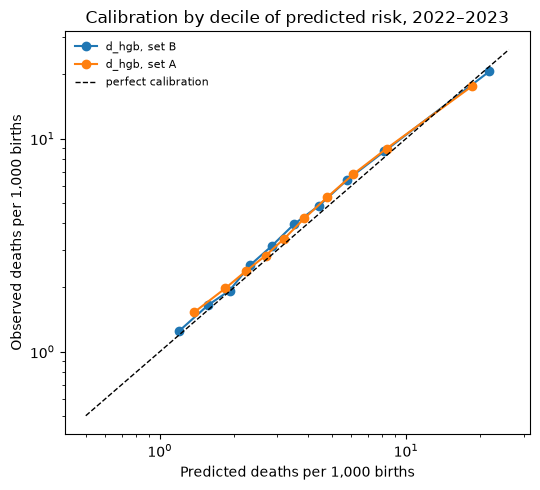

In [14]:
best = comp.filter(pl.col("is_best")).row(0, named=True)
print("CHECK 2:", "PASS" if 0.9 <= best["cal_slope"] <= 1.1 else "FAIL", f"(slope {best['cal_slope']:.3f})")
dec = pl.read_csv(R / "part1_calibration_deciles.csv")
fig, ax = plt.subplots(figsize=(5.5, 5))
for m, d in dec.group_by("model", maintain_order=True):
    ax.plot(d["mean_predicted"] * 1000, d["observed_rate"] * 1000, "o-", label=m[0].replace("|", ", set "))
lim = [0.5, max(dec["observed_rate"].max(), dec["mean_predicted"].max()) * 1000 * 1.2]
ax.plot(lim, lim, "k--", lw=1, label="perfect calibration")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Predicted deaths per 1,000 births"); ax.set_ylabel("Observed deaths per 1,000 births")
ax.set_title("Calibration by decile of predicted risk, 2022–2023"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "part1_calibration.png", dpi=150); plt.show()

**Result. Check 2 PASSES** under the pre-set rule: the slope is 0.942 (95% CI 0.934–0.951).

Two honest notes:
- The interval excludes 1, so the predictions are slightly too spread out: the highest-risk group is a little over-predicted (21.8 predicted vs 20.7 observed per 1,000 births), and the middle groups are a little under-predicted (for example 3.5 vs 4.0 in decile 6).
- Overall, observed deaths are 3% above predicted deaths (observed/expected 1.03). The 2022–2023 population has more risk factors than the training years.

The top decile of predicted risk holds 15,001 of the 40,011 test deaths (37%) in 10% of the births.

## 5. Each test year separately

**Why.** The maternal risk factors rise from year to year (see `02_table1`). If a model gets worse or less calibrated in 2023 than in 2022, that shows the cost of time shift.

In [15]:
pl.read_csv(R / "part1_test_years.csv").filter(~pl.col("model").str.starts_with("a_")).select(
    "test_year", "model", "pr_auc", "roc_auc", "cal_intercept", "cal_slope", "observed_over_expected").sort("model", "test_year")

test_year,model,pr_auc,roc_auc,cal_intercept,cal_slope,observed_over_expected
i64,str,f64,f64,f64,f64,f64
2022,"""b_age_race_logistic|-""",0.0086,0.6103,-0.0035,1.0388,0.9966
2023,"""b_age_race_logistic|-""",0.0088,0.6111,-0.0064,1.0687,0.9937
2022,"""c_logistic|A""",0.0182,0.7012,0.0717,0.9689,1.0734
2023,"""c_logistic|A""",0.0181,0.6985,0.0853,0.9594,1.0880
2022,"""c_logistic|B""",0.0239,0.7174,0.0794,0.9490,1.0811
2023,"""c_logistic|B""",0.0239,0.7159,0.1126,0.9478,1.1171
2022,"""d_hgb|A""",0.0292,0.7112,0.0403,0.9438,1.0404
2023,"""d_hgb|A""",0.0297,0.7101,0.0371,0.9438,1.0371
2022,"""d_hgb|B""",0.0376,0.7389,0.0258,0.9380,1.0255


**Result.** Boosting is stable from 2022 to 2023 (PR-AUC 0.0376 and 0.0386; slope 0.938 and 0.946). Logistic regression drifts more: its observed/expected ratio rises from 1.08 to 1.12, so it under-predicts more in the later year.

## 6. Subgroups (best model)

**What.** Performance and calibration by mother's race/Hispanic origin and by payment source. `observed_over_expected` above 1 means the model *under*-predicts risk in that group.

**Why.** A model can be accurate on average but unfair for one group.

In [16]:
RACE = {1: "NH White", 2: "NH Black", 3: "NH AIAN", 4: "NH Asian", 5: "NH NHOPI", 6: "NH multiple", 7: "Hispanic"}
PAY = {1: "Medicaid", 2: "Private", 3: "Self-pay", 4: "Other"}
sub = pl.read_csv(R / "part1_subgroups.csv")
sub.with_columns(group=pl.when(pl.col("variable") == "race").then(pl.col("code").replace_strict(RACE, default="Unknown", return_dtype=pl.Utf8))
                       .otherwise(pl.col("code").replace_strict(PAY, default="Unknown", return_dtype=pl.Utf8))) \
   .select("variable", "group", "births", "deaths", "pr_auc", "roc_auc", "observed_over_expected")

variable,group,births,deaths,pr_auc,roc_auc,observed_over_expected
str,str,i64,i64,f64,f64,f64
"""race""","""NH White""",3627790,16103,0.0301,0.7322,1.0430
"""race""","""NH Black""",1002933,10695,0.0561,0.7087,1.0053
"""race""","""NH AIAN""",50292,458,0.0328,0.6844,1.1490
"""race""","""NH Asian""",434732,1497,0.0219,0.6961,1.0484
"""race""","""NH NHOPI""",20237,168,0.0290,0.6546,1.0905
"""race""","""NH multiple""",177369,1152,0.0294,0.7124,1.0456
"""race""","""Hispanic""",1882621,9104,0.0276,0.7081,1.0318
"""race""","""Unknown""",67801,834,0.1062,0.7784,0.9461
"""pay""","""Medicaid""",2981934,21617,0.0366,0.7117,1.0338


**Result.** Ranking quality (ROC-AUC) ranges from 0.65 (NH NHOPI, 168 deaths) to 0.73 (NH White). Calibration is close to 1 for the large groups (NH Black 1.01, Hispanic 1.03, NH White 1.04). The model under-predicts risk for NH American Indian/Alaska Native births by 15% (observed/expected 1.15, 458 deaths) and for NH NHOPI by 9%. These groups are small, so their estimates are less certain, but the direction should be reported. Births with unknown race or payment have a very high PR-AUC (0.09–0.11): missing information on the certificate is itself a marker of risk.

## 7. Which items carry predictive value?

**What.** *Permutation importance*: we shuffle one item across test births and measure how much PR-AUC drops (20 repeats). A large drop means the model relies on that item. For speed this uses all test deaths and 1 in 10 test survivors (weighted ×10). The top 10 are then confirmed by *drop-group refits*: the model is retrained without the item and tested again.

**Important.** Importance means predictive value, **not** cause. An item can predict well because it is a marker of something else (for example, payment source marks income).

In [17]:
def stage_importance():
    best = best_model_key()
    kind = best.split("|")[0]
    feats = SETS["B"]
    model = joblib.load(WORK / f"model_{kind}_B.joblib")
    te = pl.read_parquet(WORK / "test.parquet")
    # subsample for permutation: all deaths + 1 in 10 survivors (weight 10)
    sub = te.filter(pl.col("death") | pl.col("sampled"))
    Xs = sub.select(feats).to_numpy().astype(np.float32)
    ys = sub["death"].to_numpy().astype(np.float64)
    ws = np.where(ys == 1, 1.0, float(SURVIVOR_SAMPLE))
    base_ap = SortedScores(ys, predict(model, Xs)).metrics(ws)[0]
    rng = np.random.default_rng(SEED)
    rows = []
    for j, f in enumerate(feats):
        drops = []
        for _ in range(N_PERM):
            Xp = Xs.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base_ap - SortedScores(ys, predict(model, Xp)).metrics(ws)[0])
        rows.append({"feature": f, "pr_auc_drop_mean": float(np.mean(drops)), "pr_auc_drop_sd": float(np.std(drops))})
        log("perm", f, round(np.mean(drops), 5))
    imp = pl.DataFrame(rows).sort("pr_auc_drop_mean", descending=True)
    imp.write_csv(REPORTS / "part1_importance.csv")

    # drop-group refits for the top 10 (same model type and settings, refit without the item)
    tr, _, ytr, wtr = load("train")
    y_te = te["death"].to_numpy().astype(np.float64)
    full_ap = SortedScores(y_te, predict(model, te.select(feats).to_numpy().astype(np.float32))).metrics()[0]
    params = model.get_params()
    rows = []
    for f in imp["feature"][:10].to_list():
        keep = [x for x in feats if x != f]
        if kind == "d_hgb":
            m = HistGradientBoostingClassifier(**{**params, "categorical_features": [x in TREE_CATEGORICAL for x in keep]})
        else:
            m = logistic_pipeline(keep, params["lr__C"])
        m = fit(m, tr.select(keep).to_numpy().astype(np.float32), ytr, wtr)
        ap = SortedScores(y_te, predict(m, te.select(keep).to_numpy().astype(np.float32))).metrics()[0]
        rows.append({"feature": f, "test_pr_auc_without": ap, "test_pr_auc_full": full_ap, "drop": full_ap - ap})
        log("drop-refit", f, round(full_ap - ap, 5))
    pl.DataFrame(rows).write_csv(REPORTS / "part1_dropgroup.csv")

    # leakage: each input alone. Score = training death rate for its value (numbers in 50 quantile bins).
    rows = []
    for f in feats:
        xtr, xte = tr[f].to_numpy(), te[f].to_numpy()
        if KIND[f] == "num" and len(np.unique(xtr[~np.isnan(xtr)])) > 50:
            edges = np.unique(np.nanquantile(xtr, np.linspace(0, 1, 51)))
            btr, bte = np.digitize(xtr, edges), np.digitize(xte, edges)
        else:
            btr, bte = xtr, xte
        btr = np.where(np.isnan(btr), -999, btr)
        bte = np.where(np.isnan(bte), -999, bte)
        rate = (pl.DataFrame({"b": btr, "y": ytr, "w": wtr})
                .group_by("b").agg(r=(pl.col("y") * pl.col("w")).sum() / pl.col("w").sum()))
        score = (pl.DataFrame({"b": bte}).join(rate, on="b", how="left")["r"]
                 .fill_null(float(np.sum(ytr * wtr) / np.sum(wtr))).to_numpy())
        auc = SortedScores(y_te, score).metrics()[1]
        rows.append({"feature": f, "roc_auc_alone": auc, "flag_over_0_80": auc > 0.80})
    pl.DataFrame(rows).sort("roc_auc_alone", descending=True).write_csv(REPORTS / "part1_leakage.csv")
    log("done importance")


run_stage(stage_importance, [REPORTS / "part1_importance.csv", REPORTS / "part1_dropgroup.csv", REPORTS / "part1_leakage.csv"])

23:20:18 perm mage 0.00063


23:21:23 perm race 0.00132


23:22:32 perm nativity 0.00078


23:23:42 perm educ 0.00272


23:24:55 perm marital 0.00072


23:26:03 perm pay 0.00022


... (36 outputs left out)

00:09:10 drop-refit educ 0.00076


00:10:35 drop-refit wic 0.00077


00:12:15 drop-refit ghype 0.00092


00:12:27 done importance


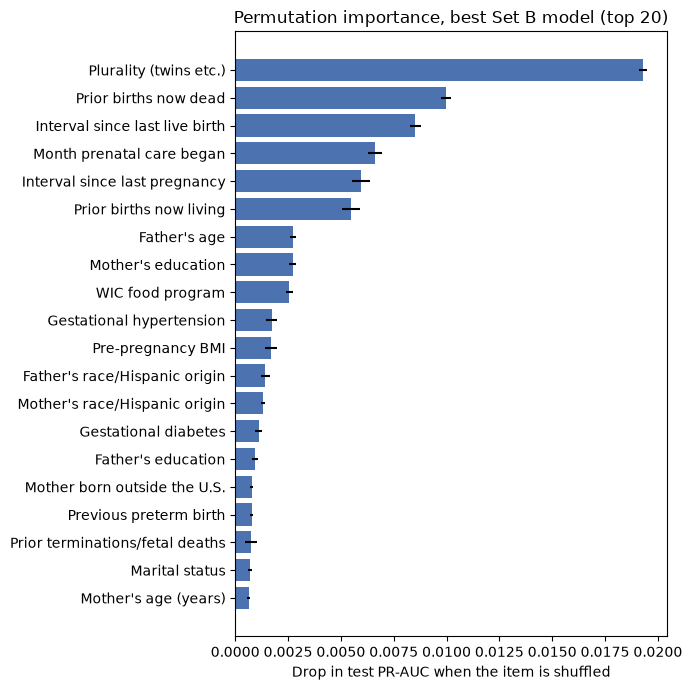

label,pr_auc_drop_mean,pr_auc_drop_sd,refit_drop
str,f64,f64,f64
"""Plurality (twins etc.)""",0.0193,0.0002,0.0032
"""Prior births now dead""",0.0100,0.0002,0.0006
"""Interval since last live birth""",0.0085,0.0003,0.0010
"""Month prenatal care began""",0.0066,0.0003,0.0036
"""Interval since last pregnancy""",0.0060,0.0004,0.0017
"""Prior births now living""",0.0055,0.0004,-0.0001
"""Father's age""",0.0027,0.0001,0.0007
"""Mother's education""",0.0027,0.0002,0.0008
"""WIC food program""",0.0026,0.0002,0.0008


In [18]:
imp = pl.read_csv(R / "part1_importance.csv").with_columns(label=pl.col("feature").replace_strict(LABEL))
drop = pl.read_csv(R / "part1_dropgroup.csv").select("feature", pl.col("drop").alias("refit_drop"))
tab = imp.join(drop, on="feature", how="left")
fig, ax = plt.subplots(figsize=(7, 7))
t = tab.head(20).reverse()
ax.barh(t["label"], t["pr_auc_drop_mean"], xerr=t["pr_auc_drop_sd"], color="#4C72B0")
ax.set_xlabel("Drop in test PR-AUC when the item is shuffled"); ax.set_title("Permutation importance, best Set B model (top 20)")
fig.tight_layout(); fig.savefig(FIG / "part1_importance.png", dpi=150); plt.show()
tab.select("label", "pr_auc_drop_mean", "pr_auc_drop_sd", "refit_drop")

**Result.**
- **Plurality is the strongest item** by far (PR-AUC drop 0.019). Twins and triplets have a much higher risk.
- **Birth history (prior births now dead, intervals, prior births now living)** comes next. `priordead` has a large permutation drop (0.010) but a small refit drop (0.0006). The reason: it shares information with `priorlive` and birth order. When one is removed, the model uses the others. Shuffling one alone creates impossible combinations, so it exaggerates.
- **Pre-pregnancy hypertension and diabetes rank low** (drop ≈ 0.0001). This does **not** mean they are harmless: only 1–3% of mothers have them, so they help little to rank all births. Part 2 measures how much they raise the risk for the mothers who have them.
- **Cohort year has zero importance.** The tree model cannot extrapolate to 2022–2023, so the year adds nothing.
- **Infections add nothing.**

**A problem found here:** `precare` (month prenatal care began), `illb` and `ilp` (birth intervals) are in the top 5. All three depend on how long the pregnancy lasted. Care cannot begin after the birth, and CDC measures the intervals up to *this* birth, so a preterm birth shortens them. This is timing leakage, like the total number of visits that the plan already excluded. Section 8 measures its size.

### Pre-set check 3: leakage

**Rule.** If any single item alone reaches ROC-AUC > 0.80, it may contain information from after delivery, and it must be investigated before results are reported. Each item's score is the training death rate for its value.

In [19]:
leak = pl.read_csv(R / "part1_leakage.csv").with_columns(label=pl.col("feature").replace_strict(LABEL))
print("CHECK 3:", "PASS" if not (leak["roc_auc_alone"] > 0.80).any() else "INVESTIGATE")
leak.select("label", "roc_auc_alone", "flag_over_0_80")

CHECK 3: PASS


label,roc_auc_alone,flag_over_0_80
str,f64,f64
"""Father's education""",0.6262,0.0000
"""Father's race/Hispanic origin""",0.6151,0.0000
"""Mother's education""",0.6084,0.0000
"""Father's age""",0.6005,0.0000
"""Month prenatal care began""",0.5904,0.0000
"""Mother's race/Hispanic origin""",0.5872,0.0000
"""Marital status""",0.5839,0.0000
"""Interval since last pregnancy""",0.5791,0.0000
"""Interval since last live birth""",0.5754,0.0000


**Result. Check 3 PASSES** as defined: no single item reaches ROC-AUC 0.80 (the highest is father's education, 0.63). The check was too weak, however, to detect the timing problem in the previous section. Leakage spread over several items, each with a small signal, does not show up in a single-item test.

## 8. Post-hoc sensitivity: without the timing items

**What.** After section 7, we refit the best boosting settings of Sets A and B **without** `precare`, `illb` and `ilp`, and test them on the same 2022–2023 births (1,000 paired bootstrap resamples).

**Why.** These items depend on the length of the pregnancy, so they leak a little information about preterm birth. This analysis was **not** in the original plan; it is recorded in the change log of `plan/analysis_plan.md`.

In [20]:
TIMING_ITEMS = ["precare", "illb", "ilp"]   # depend on pregnancy length (see change log, 23 Nov 2026)


def stage_strict():
    """Post-hoc: best boosting settings of Sets A and B, refit without the timing items."""
    tun = pl.read_csv(REPORTS / "part1_tuning.csv")
    tr, _, ytr, wtr = load("train")
    te = pl.read_parquet(WORK / "test.parquet")
    y = te["death"].to_numpy().astype(np.float64)
    pr = test_predictions()
    rows, preds = [], {}
    for s in ("A", "B"):
        params = json.loads(tun.filter((pl.col("model") == "d_hgb") & (pl.col("set") == s))
                            .sort("tune_pr_auc", descending=True)["params"][0])
        feats = [f for f in SETS[s] if f not in TIMING_ITEMS]
        m = fit(hgb(feats, params), tr.select(feats).to_numpy().astype(np.float32), ytr, wtr)
        p = predict(m, te.select(feats).to_numpy().astype(np.float32))
        preds[f"d_hgb|{s}_strict"] = p
        preds[f"d_hgb|{s}"] = pr[f"d_hgb|{s}"].to_numpy()
        log("strict fitted", s)
    srt = {k: SortedScores(y, v) for k, v in preds.items()}
    rng = np.random.default_rng(SEED)
    boot = {k: [] for k in preds}
    for r in range(N_BOOT):
        w = rng.poisson(1.0, len(y)).astype(np.float64)
        for k in preds:
            boot[k].append(srt[k].metrics(w)[0])
        if r % 200 == 0:
            log("bootstrap", r)
    boot = {k: np.array(v) for k, v in boot.items()}
    for k, p in preds.items():
        ap, auc = srt[k].metrics()
        lo, hi = np.percentile(boot[k], [2.5, 97.5])
        rows.append({"model": k, "pr_auc": ap, "pr_auc_lo": lo, "pr_auc_hi": hi, "roc_auc": auc,
                     "brier": brier(y, p), **calibration(y, p)})
    for s in ("A", "B"):
        d = boot[f"d_hgb|{s}"] - boot[f"d_hgb|{s}_strict"]
        rows.append({"model": f"difference {s} - {s}_strict", "pr_auc": float(np.mean(d)),
                     "pr_auc_lo": np.percentile(d, 2.5), "pr_auc_hi": np.percentile(d, 97.5)})
    pl.DataFrame(rows).write_csv(REPORTS / "part1_strict.csv")
    log("done strict")


run_stage(stage_strict, [REPORTS / "part1_strict.csv"])

00:13:45 strict fitted A


00:15:02 strict fitted B


00:15:07 bootstrap 0


00:16:52 bootstrap 200


00:18:43 bootstrap 400


00:20:33 bootstrap 600


00:22:23 bootstrap 800


00:24:16 done strict


In [21]:
pl.read_csv(R / "part1_strict.csv").select("model", "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "cal_intercept", "cal_slope", "observed_over_expected")

model,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,cal_intercept,cal_slope,observed_over_expected
str,f64,f64,f64,f64,f64,f64,f64
"""d_hgb|A_strict""",0.0191,0.0184,0.0199,0.7008,0.0415,0.9366,1.0418
"""d_hgb|A""",0.0294,0.0281,0.0308,0.7107,0.0388,0.9438,1.0388
"""d_hgb|B_strict""",0.0300,0.0288,0.0314,0.7219,0.0340,0.9368,1.0339
"""d_hgb|B""",0.0380,0.0364,0.0396,0.7392,0.0298,0.9420,1.0295
"""difference A - A_strict""",0.0103,0.0092,0.0114,null,null,null,null
"""difference B - B_strict""",0.0080,0.0072,0.0089,null,null,null,null


**Result.** The timing items matter a lot.

| Model | PR-AUC (95% CI) | ROC-AUC |
|---|---|---|
| Boosting, Set B (main, pre-registered) | 0.0380 (0.0364–0.0396) | 0.739 |
| Boosting, Set B strict (no `precare`, `illb`, `ilp`) | **0.0300 (0.0288–0.0314)** | 0.722 |
| Boosting, Set A | 0.0294 (0.0281–0.0308) | 0.711 |
| Boosting, Set A strict | **0.0191 (0.0184–0.0199)** | 0.701 |

The three items carry about one fifth (Set B) to one third (Set A) of the PR-AUC. The strict models are still well calibrated (slope 0.937) and still beat model (b) by about 3.4 times. **For the thesis text, the strict numbers are the more honest estimate of what is known before delivery.** The main numbers stay in the thesis because they were pre-registered, and the difference itself is a finding about leakage in birth-certificate data.

## Summary

- **Main finding.** Information known before delivery predicts infant death clearly better than mother's age and race alone. The best model (gradient boosting) reaches PR-AUC 0.030–0.038 (5–7 times the base rate) and ROC-AUC 0.72–0.74 in 2022–2023 births that it never saw, with good calibration.
- **Pre-set checks.** Check 1 (beats model b): PASS. Check 2 (calibration slope 0.9–1.1): PASS (0.94). Check 3 (no single item ROC-AUC > 0.80): PASS, but this check missed a timing leakage that the importance analysis found.
- **Most predictive items.** Plurality, birth history and (for the leaky part) the start of prenatal care and birth intervals. Pre-pregnancy hypertension and diabetes help little for *ranking* all births, because they are rare.
- **Fairness.** Risk is under-predicted for NH AIAN (15%) and NH NHOPI (9%) births.
- **Open issues.** (1) Report the strict models next to the main ones. (2) Explain in the limitations why a model cannot reach high accuracy without gestational age and birth weight. (3) Part 2 asks the different question of how much the three maternal factors change the risk.
- **Next notebook.** `04_association.ipynb` (Part 2).